In [1]:
import os

import scipy.io
import pandas as pd

import json

from popy.io_tools_helpers import *  # behavior preprocessing functions
from popy.config import PROJECT_PATH_LOCAL

def print_event_numbers(raw_df):
    # count number of 100, 65 and 66 events
    n_100 = (raw_df['Event'] == 100).sum()
    n_101 = (raw_df['Event'] == 101).sum()
    n_65 = (raw_df['Event'] == 65).sum()
    n_66 = (raw_df['Event'] == 66).sum()
    n_252 = (raw_df['Event'] == 252).sum()
    n_51 = (raw_df['Event'] == 51).sum()
    n_52 = (raw_df['Event'] == 52).sum()
    n_53 = (raw_df['Event'] == 53).sum()
    n_7 = (raw_df['Event'] == 7).sum()

    print(f"Number of 100 events: {n_100}")
    print(f"Number of 101 events: {n_101}")
    print(f"Total number of outcomes: {n_65+n_66}")
    print(f"\tNumber of 65 events: {n_65}")
    print(f"\tNumber of 66 events: {n_66}")
    print(f"Number of 252 events: {n_252}")

    print(f"Total number of best targets: {n_51+n_52+n_53}")
    print(f"\tNumber of 51 events: {n_51}")
    print(f"\tNumber of 52 events: {n_52}")
    print(f"\tNumber of 53 events: {n_53}")

    print(f"Number of block starts: {n_7}")

def run_sanity(raw_behav):
    trial_start_ids = np.where(raw_behav[:, 0] == 100)[0]
    trial_end_ids = np.where(raw_behav[:, 0] == 101)[0]
    fb_ids = np.where((raw_behav[:, 0] == 65) | (raw_behav[:, 0] == 66))[0]
    interrupted_ids = np.where(raw_behav[:, 0] == 252)[0]

    # the number of trial starts and trial ends do not match. normally the IDs should be alternating, but here we have some
    # outliers. print those that are not alternating
    data_ok = True
    for i in range(len(trial_end_ids)-1):
        trial_end_curr = trial_end_ids[i]
        trial_end_next = trial_end_ids[i+1]
        trial_start_between = trial_start_ids[(trial_start_ids > trial_end_curr) & (trial_start_ids < trial_end_next)]
        if len(trial_start_between) == 0:
            print(f"Trial end at index {trial_end_curr} is followed by no trial start at indices {trial_start_between} before the next trial end at index {trial_end_next}.")
            data_ok = False
    if data_ok:
        print("Trial start and end events are alternating correctly.")

    data_ok = True
    for i in range(len(trial_start_ids)-1):
        trial_start_curr = trial_start_ids[i]
        trial_start_next = trial_start_ids[i+1]
        trial_end_between = trial_end_ids[(trial_end_ids > trial_start_curr) & (trial_end_ids < trial_start_next)]
        if len(trial_end_between) == 0:
            print(f"Trial start at index {trial_start_curr} is followed by no trial end at indices {trial_end_between} before the next trial start at index {trial_start_next}.")
            data_ok = False
    if data_ok:
        print("Trial start and end events are alternating correctly.")

    # check for trials with no feedback (no 65 or 66 events) and print their indices
    data_ok = True
    for i in range(len(trial_start_ids)-1):
        trial_start_curr = trial_start_ids[i]
        trial_start_next = trial_start_ids[i+1]
        fb_between = fb_ids[(fb_ids > trial_start_curr) & (fb_ids < trial_start_next)]
        interrupted_between = interrupted_ids[(interrupted_ids > trial_start_curr) & (interrupted_ids < trial_start_next)]
        if len(fb_between) == 0 and len(interrupted_between) == 0:
            print(f"Trial start at index {trial_start_curr} is followed by no feedback or interruption.")
            data_ok = False
    if data_ok:
        print("All trials have feedback or interruption events.")

def add_missing_252_events(df):
    # Add a 252 event after a 100 event when the interval before the next
    # 100 contains neither feedback (65/66) nor an existing 252 event.
    # Iterate backwards so inserted rows do not invalidate earlier indices.
    trial_start_ids = df.index[df["Event"].eq(100)]
    added_252_rows = 0

    for i in reversed(range(len(trial_start_ids) - 1)):
        trial_start_curr = trial_start_ids[i]
        trial_start_next = trial_start_ids[i + 1]

        interval_events = df.iloc[
            trial_start_curr + 1 : trial_start_next
        ]["Event"]

        has_feedback = interval_events.isin([65, 66]).any()
        has_252 = interval_events.eq(252).any()

        if not has_feedback and not has_252:
            new_row = pd.DataFrame({
                "Event": [252],
                "Time": [df.iloc[trial_start_curr]["Time"] + 0.001],
            })

            df = pd.concat(
                [
                    df.iloc[: trial_start_curr + 1],
                    new_row,
                    df.iloc[trial_start_curr + 1 :],
                ],
                ignore_index=True,
            )
            added_252_rows += 1

    print(f"Added {added_252_rows} missing 252 events.")

    return df

def add_missing_100_events(df):
        # Add a 100 event when no 100 occurs between two consecutive 101 events.
        # Iterate backwards so inserted rows do not invalidate earlier indices.
        trial_end_ids = df.index[df["Event"].eq(101)]
        added_rows = 0
        for i in reversed(range(len(trial_end_ids) - 1)):
            trial_end_curr = trial_end_ids[i]
            trial_end_next = trial_end_ids[i + 1]
        
            has_100_between = df.iloc[
                trial_end_curr + 1 : trial_end_next
            ]["Event"].eq(100).any()
        
            if not has_100_between:
                new_row = pd.DataFrame({
                    "Event": [100],
                    "Time": [df.iloc[trial_end_curr]["Time"] + 0.001],
                })
        
                df = pd.concat(
                    [
                        df.iloc[: trial_end_curr + 1],
                        new_row,
                        df.iloc[trial_end_curr + 1 :],
                    ],
                    ignore_index=True,
                )
                added_rows += 1
        
        print(f"Added {added_rows} missing 100 events after 101 events.")

        return df

def _load_behavioral_data(mat_file_path):
    # Load .mat file output
    mat_data = scipy.io.loadmat(mat_file_path)
    data = mat_data['behavioral_table']

    # Create DataFrame with all validation columns
    df = pd.DataFrame(data, columns=['EventCode', 'PosixTimestamp', 'OrigTimeStampSec', 'FileID'])

    # Format data types
    df['Event'] = df['EventCode'].astype(int)
    df['FileID'] = df['FileID'].astype(int)
    df['FileFormatted'] = df['FileID'].apply(lambda x: f"{x:03d}")  # e.g., '001', '002'

    # referencePosix is the first timestamp in the file, used to calculate relative time
    referencePosix = df['PosixTimestamp'].iloc[0]
    df['PosixTimestamp'] = df['PosixTimestamp'] - referencePosix  # relative to first event
    #df['DateTime_UTC'] = pd.to_datetime(df['PosixTimestamp'], unit='s', utc=True)
    #df['DateTime_Local'] = df['DateTime_UTC'].dt.tz_convert('Europe/Paris')
    # float time value (relative to first event) in seconds, with millisecond precision
    df['Time'] = df['PosixTimestamp'].astype(float)

    # Reorder columns
    df = df[['Event', 'Time']]

    # cut all before 255 event, cut all rows below 102 event happens
    id_255 = df[df['Event'] == 255].index[-1]
    id_102 = df[df['Event'] == 102].index[0]
    df = df.iloc[id_255:id_102+1].reset_index(drop=True)

    # remove duplicate 101 events (keep the first one)
    trial_end_ids = df.index[df["Event"].eq(101)]
    ids_to_drop = [trial_end_ids[i] for i in range(1, len(trial_end_ids)) if trial_end_ids[i] == trial_end_ids[i-1] + 1]
    df = df.drop(ids_to_drop).reset_index(drop=True)
    print(f"Dropping {len(ids_to_drop)} duplicate 101 events.")

    # swap 8 to 7
    df.loc[df['Event'] == 8, 'Event'] = 7

    # add missing events
    df = add_missing_100_events(df)
    df = add_missing_252_events(df)
    
    return df, referencePosix


/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-h79m97px because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
# load .mat behavioral data
raw_df, referencePosix = _load_behavioral_data('/workspace/uzsombi/inserm/PoPy/data/recordings/yuri_raw/example_session/behavioral_events.mat')

raw_df, referencePosix

Dropping 1 duplicate 101 events.
Added 3 missing 100 events after 101 events.
Added 2 missing 252 events.


(       Event         Time
 0        255   394.265266
 1          7   394.344833
 2         52   394.347433
 3        100   394.390266
 4         52   394.391033
 ...      ...          ...
 11245    125  3663.545100
 11246     65  3664.069800
 11247    144  3664.516966
 11248    101  3664.520333
 11249    102  3664.534867
 
 [11250 rows x 2 columns],
 1706777127.7764335)

In [5]:
# load .mat behavioral data
raw_df, referencePosix = _load_behavioral_data('/workspace/uzsombi/inserm/PoPy/data/recordings/yuri_raw/example_session/behavioral_events.mat')

# convert df to numpy array
raw_behav = raw_df.to_numpy()
run_sanity(raw_behav)

# extract single trials
behav_pd = reformat_behav(raw_behav)

# extract key events from trials
times_df = extract_behav_timestamps(raw_behav)  # extract timestamps
events_df = extract_behav_events(raw_behav)   # extract events

# concatenate times and events and return
joint_df = times_df.join(events_df.set_index('trial_id'), on='trial_id')

# add monkey and session info, replace it to the first 2 cols
joint_df['monkey'] = 'yuri'
joint_df['injection'] = 'NA'
joint_df['session'] = 'NA' 
# put these 3 cols in the front
cols = ['monkey', 'injection', 'session'] + [col for col in joint_df.columns if col not in ['monkey', 'injection', 'session']]
joint_df = joint_df[cols]

# remove too short blocks from beginning and end of session
# a block is too short if it is shorter than 30 trials
joint_df = chop_trunctuated_blocks(joint_df)

# save df at 
floc = os.path.join(PROJECT_PATH_LOCAL, 'data', 'processed', 'behavior', 'yuri_example_session.csv')
joint_df.to_csv(floc, index=False)
print(f"Processed behavioral data saved to {floc}")
# save referencePosix in json file
json_floc = os.path.join(PROJECT_PATH_LOCAL, 'data', 'processed', 'behavior', 'yuri_example_session_meta.json')
with open(json_floc, 'w') as f:
    json.dump({'referencePosix': referencePosix}, f)

joint_df

Dropping 1 duplicate 101 events.
Added 3 missing 100 events after 101 events.
Added 2 missing 252 events.
Trial start and end events are alternating correctly.
Trial start and end events are alternating correctly.
All trials have feedback or interruption events.
Processed behavioral data saved to /workspace/uzsombi/inserm/PoPy/data/processed/behavior/yuri_example_session.csv


,monkey,injection,session,trial_id,n_target_touches,trial_start_time,lever_touch_time,lever_validation_time,lever_release_time,target_touch_time,target_validation_time,feedback_time,trial_end_time,block_id,best_target,target,feedback
0,yuri,NA,NA,0,1.0,394.3903,396.2241,397.7437,398.4360,398.7708,399.3049,399.8228,400.7721,0,2,3.0,True
1,yuri,NA,NA,1,1.0,400.7721,401.1234,402.6442,403.4003,403.6064,404.1375,404.6551,405.5522,0,2,3.0,False
2,yuri,NA,NA,2,1.0,405.5522,414.2937,415.8090,416.8514,417.0904,417.6184,418.1376,419.0831,0,2,3.0,False
3,yuri,NA,NA,3,1.0,419.0831,420.3965,421.9066,423.3787,423.6223,424.1507,424.6791,425.7507,0,2,3.0,True
4,yuri,NA,NA,4,1.0,425.7507,426.1087,427.6268,428.3401,428.5600,429.0853,429.6005,430.5545,0,2,3.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
505,yuri,NA,NA,505,1.0,3478.9606,3479.1070,3480.6328,3481.7974,3482.0519,3482.5716,3483.0955,3484.1359,11,2,2.0,True
506,yuri,NA,NA,506,1.0,3484.1359,3484.3395,3485.8627,3486.8855,3487.1849,3487.7528,3488.3680,3491.8889,11,2,2.0,False
507,yuri,NA,NA,507,1.0,3491.8889,3492.1643,3493.6777,3494.3022,3494.6081,3495.1340,3495.6577,3496.5908,11,2,2.0,False
508,yuri,NA,NA,508,1.0,3496.5908,3496.6680,3498.1932,3500.1386,3500.3582,3500.8812,3501.3906,3502.4288,11,2,2.0,True


/workspace/uzsombi/inserm/PoPy/popy/plotting/plotting_tools.py:829: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


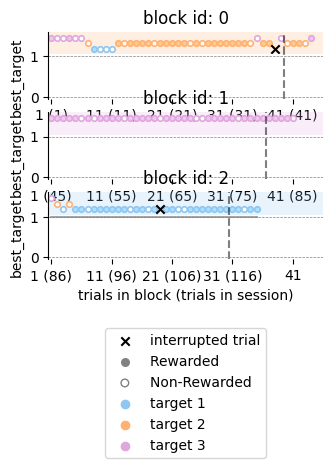

In [4]:
# plot behavior
from popy.behavior_data_tools import *
from popy.plotting.plotting_tools import show_target_selection, show_target_selection_compact

session_data = joint_df.copy()  # use the joint_df as session_data for plotting

session_data = drop_time_fields(session_data)  # drop time fields (not necessary for this plotting)

show_target_selection_compact(session_data[:120], 
                              format='paper',
                              background_values=['best_target'],   # here we tell what variable to use as background - value in this case
                              title=None, #f'monkey: {monkey}, session: {session}', 
                              show=True)